In [1]:
import pandas as pd
import numpy as np
from datetime import datetime

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [2]:
data=pd.read_csv('Data/NYC.csv', nrows=100000)
data.head()


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [3]:
data.size

1100000

In [4]:
data.shape

(100000, 11)

In [5]:
data.describe()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.53349,1.667810,-73.973464,40.751059,-73.973455,40.751947,939.864260
std,0.49888,1.317603,0.038294,0.028152,0.036625,0.032452,3004.541199
min,1.00000,0.000000,-74.533875,40.433842,-74.562355,40.441662,1.000000
25%,1.00000,1.000000,-73.991852,40.737370,-73.991394,40.735844,396.000000
50%,2.00000,1.000000,-73.981712,40.754269,-73.979782,40.754478,662.000000
75%,2.00000,2.000000,-73.967209,40.768426,-73.962919,40.769928,1076.000000
max,2.00000,6.000000,-73.334023,41.319164,-72.711395,41.311520,86390.000000


In [6]:
data.dtypes

id                        str
vendor_id               int64
pickup_datetime           str
dropoff_datetime          str
passenger_count         int64
pickup_longitude      float64
pickup_latitude       float64
dropoff_longitude     float64
dropoff_latitude      float64
store_and_fwd_flag        str
trip_duration           int64
dtype: object

In [7]:
data['vendor_id'].nunique()

2

In [8]:
data['vendor_id'].value_counts()

vendor_id
2    53349
1    46651
Name: count, dtype: int64

In [9]:
print(data['vendor_id'].unique())

[2 1]


In [10]:
data1 = data.drop(['id', 'dropoff_datetime'], axis=1)

In [11]:
print(data1['vendor_id'].unique())


[2 1]


In [12]:
data1['vendor_id'] = data1['vendor_id'].map({1: 'Uber', 2: 'Ola'})

In [13]:
data1.head()

,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,Ola,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,Uber,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,Ola,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,Ola,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,Ola,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [14]:
data1.dtypes

vendor_id                 str
pickup_datetime           str
passenger_count         int64
pickup_longitude      float64
pickup_latitude       float64
dropoff_longitude     float64
dropoff_latitude      float64
store_and_fwd_flag        str
trip_duration           int64
dtype: object

In [15]:
data1['travel_day']=pd.to_datetime(data['pickup_datetime']).apply(lambda x:x.strftime('%A'))
data1.head()

,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,travel_day
0,Ola,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,455,Monday
1,Uber,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,663,Sunday
2,Ola,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,Tuesday
3,Ola,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,429,Wednesday
4,Ola,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,435,Saturday


In [16]:
def time_bucket(x):
  hour = int(x.strftime('%H'))
  if hour < 6 or hour > 24:
    return 'night'
  elif hour < 12:
    return 'morning'
  elif hour < 18:
    return 'afternoon'
  else:
    return 'evening'

In [17]:
data1['travel_time'] = pd.to_datetime(data['pickup_datetime']).apply(lambda x:time_bucket(x))
data1.head()

,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,travel_day,travel_time
0,Ola,2016-03-14 17:24:55,1,-73.982155,40.767937,-73.964630,40.765602,N,455,Monday,afternoon
1,Uber,2016-06-12 00:43:35,1,-73.980415,40.738564,-73.999481,40.731152,N,663,Sunday,night
2,Ola,2016-01-19 11:35:24,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,Tuesday,morning
3,Ola,2016-04-06 19:32:31,1,-74.010040,40.719971,-74.012268,40.706718,N,429,Wednesday,evening
4,Ola,2016-03-26 13:30:55,1,-73.973053,40.793209,-73.972923,40.782520,N,435,Saturday,afternoon


In [18]:
data1.drop('pickup_datetime', axis =1, inplace=True)
data1.head()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,travel_day,travel_time
0,Ola,1,-73.982155,40.767937,-73.964630,40.765602,N,455,Monday,afternoon
1,Uber,1,-73.980415,40.738564,-73.999481,40.731152,N,663,Sunday,night
2,Ola,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,Tuesday,morning
3,Ola,1,-74.010040,40.719971,-74.012268,40.706718,N,429,Wednesday,evening
4,Ola,1,-73.973053,40.793209,-73.972923,40.782520,N,435,Saturday,afternoon


In [19]:
data1.isnull().sum()

vendor_id             0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
travel_day            0
travel_time           0
dtype: int64

In [20]:
data1.duplicated().sum()

np.int64(0)

OneHotEncoding

In [21]:
obj_df = data1.select_dtypes(include=['object'])
obj_df.head()

,vendor_id,store_and_fwd_flag,travel_day,travel_time
0,Ola,N,Monday,afternoon
1,Uber,N,Sunday,night
2,Ola,N,Tuesday,morning
3,Ola,N,Wednesday,evening
4,Ola,N,Saturday,afternoon


In [22]:
num_df = data1.select_dtypes(include=['float64', 'int64'])
num_df.head()

,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
0,1,-73.982155,40.767937,-73.964630,40.765602,455
1,1,-73.980415,40.738564,-73.999481,40.731152,663
2,1,-73.979027,40.763939,-74.005333,40.710087,2124
3,1,-74.010040,40.719971,-74.012268,40.706718,429
4,1,-73.973053,40.793209,-73.972923,40.782520,435


In [23]:
obj_dummies= pd.get_dummies(obj_df, drop_first=True)
obj_dummies.head()

,vendor_id_Uber,store_and_fwd_flag_Y,travel_day_Monday,travel_day_Saturday,travel_day_Sunday,travel_day_Thursday,travel_day_Tuesday,travel_day_Wednesday,travel_time_evening,travel_time_morning,travel_time_night
0,False,False,True,False,False,False,False,False,False,False,False
1,True,False,False,False,True,False,False,False,False,False,True
2,False,False,False,False,False,False,True,False,False,True,False
3,False,False,False,False,False,False,False,True,True,False,False
4,False,False,False,True,False,False,False,False,False,False,False


In [24]:
obj_dummies.shape

(100000, 11)

In [25]:
num_df.shape

(100000, 6)

In [26]:
final_df = pd.concat([obj_dummies, num_df], axis=1)
final_df.head

<bound method NDFrame.head of        vendor_id_Uber  store_and_fwd_flag_Y  travel_day_Monday  \
0               False                 False               True   
1                True                 False              False   
2               False                 False              False   
3               False                 False              False   
4               False                 False              False   
...               ...                   ...                ...   
99995            True                 False               True   
99996           False                 False              False   
99997           False                 False              False   
99998            True                 False               True   
99999           False                 False              False   

       travel_day_Saturday  travel_day_Sunday  travel_day_Thursday  \
0                    False              False                False   
1                    False           

In [27]:
final_df.shape

(100000, 17)

In [28]:
x = final_df.drop('trip_duration', axis =1)
x

,vendor_id_Uber,store_and_fwd_flag_Y,travel_day_Monday,travel_day_Saturday,travel_day_Sunday,travel_day_Thursday,travel_day_Tuesday,travel_day_Wednesday,travel_time_evening,travel_time_morning,travel_time_night,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
0,False,False,True,False,False,False,False,False,False,False,False,1,-73.982155,40.767937,-73.964630,40.765602
1,True,False,False,False,True,False,False,False,False,False,True,1,-73.980415,40.738564,-73.999481,40.731152
2,False,False,False,False,False,False,True,False,False,True,False,1,-73.979027,40.763939,-74.005333,40.710087
3,False,False,False,False,False,False,False,True,True,False,False,1,-74.010040,40.719971,-74.012268,40.706718
4,False,False,False,True,False,False,False,False,False,False,False,1,-73.973053,40.793209,-73.972923,40.782520
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,True,False,True,False,False,False,False,False,True,False,False,1,-73.958275,40.772923,-73.965645,40.763599
99996,False,False,False,False,False,True,False,False,False,True,False,6,-73.958778,40.766708,-73.956139,40.779018
99997,False,False,False,False,False,True,False,False,False,False,True,1,-73.945961,40.780510,-73.861778,40.768421
99998,True,False,True,False,False,False,False,False,False,True,False,1,-73.983887,40.738544,-73.970932,40.751678


In [29]:
y=final_df['trip_duration']
y

0         455
1         663
2        2124
3         429
4         435
         ... 
99995     313
99996     738
99997     968
99998     597
99999     205
Name: trip_duration, Length: 100000, dtype: int64

In [30]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.25, random_state=42)

In [31]:
reg = LinearRegression()
reg.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[ -183.97, 147.2 , -77.01,...,-3569.12, 2998.36,-3199.8 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['vendor_id_Uber','store_and_fwd_flag_Y','travel_day_Monday',..., 'pickup_latitude','dropoff_longitude','dropoff_latitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.702e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)


In [32]:
ypred=reg.predict(x_test)
ypred

array([1185.93098712,  883.96456073,  600.52833292, ..., 2252.29485053,
        947.33585676,  944.42113455], shape=(25000,))

In [33]:
mean_absolute_error(y_test, ypred)

567.0104780375725

In [34]:
mean_squared_error(y_test, ypred)

9773273.326005908

In [35]:
np.sqrt(mean_squared_error(y_test,ypred))

np.float64(3126.2234926514625)

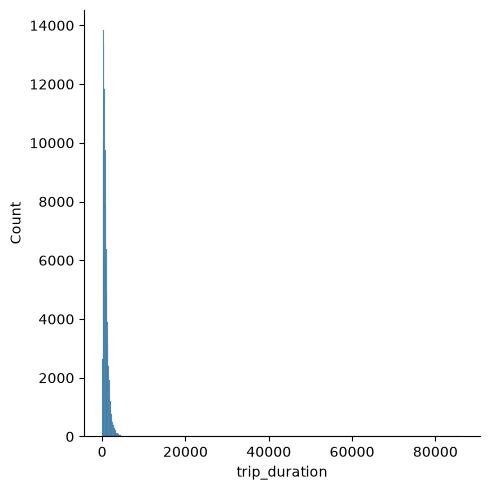

In [36]:
sns.displot(y)

<Axes: ylabel='trip_duration'>

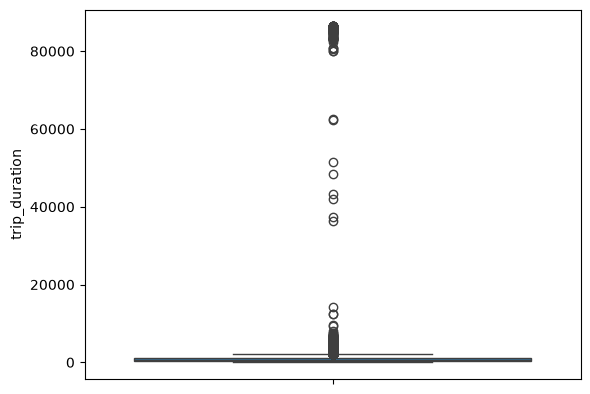

In [37]:
sns.boxplot(y)

In [38]:
y.describe()

count    100000.000000
mean        939.864260
std        3004.541199
min           1.000000
25%         396.000000
50%         662.000000
75%        1076.000000
max       86390.000000
Name: trip_duration, dtype: float64

In [39]:
r2_score(y_test, ypred)

0.010429723169142813

In [40]:
npd = final_df['trip_duration'].describe()
UT = npd['75%']+1.5*(npd['75%']-npd['25%'])
LT = npd['25%']-1.5*(npd['75%']-npd['25%'])

In [41]:
UT

np.float64(2096.0)

In [42]:
LT

np.float64(-624.0)

In [43]:
remove_index = final_df[final_df['trip_duration']>2096].index.tolist()

In [44]:
final_df.drop(remove_index, axis=0,inplace=True)

In [45]:
final_df.shape

(94960, 17)

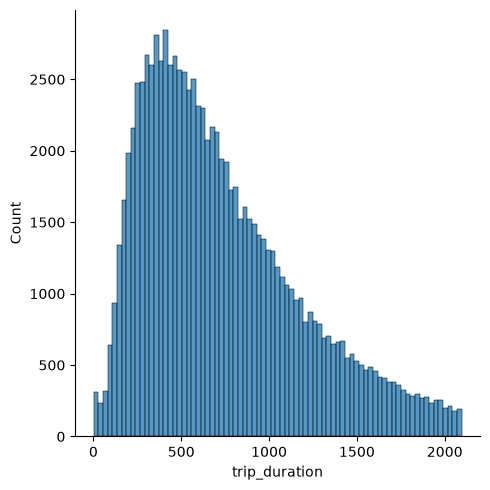

In [46]:
sns.displot(final_df['trip_duration'])

<Axes: ylabel='trip_duration'>

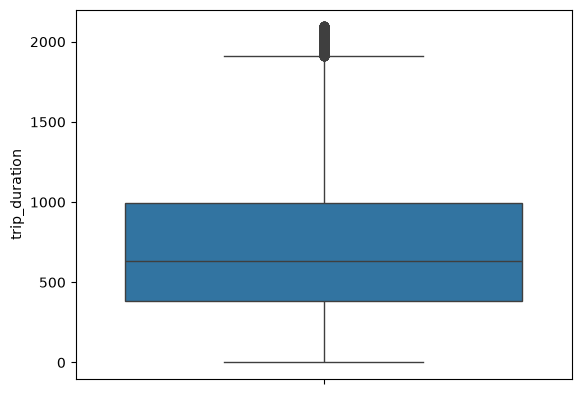

In [47]:
sns.boxplot(final_df['trip_duration'])

In [48]:
x= final_df.drop('trip_duration', axis = 1)
y= final_df['trip_duration']


In [49]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25, random_state=42)

In [50]:
reg = LinearRegression()
reg.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](16,)","[ -2.7 , 95.16, -47.27,...,-1546.2 , 2191.58,-1825.12]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['vendor_id_Uber','store_and_fwd_flag_Y','travel_day_Monday',..., 'pickup_latitude','dropoff_longitude','dropoff_latitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.035e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)


In [51]:
ypred= reg.predict(x_test)
ypred

array([808.06557786, 692.71787255, 925.61342725, ..., 767.49345951,
       694.31653238, 665.38263522], shape=(23740,))

In [52]:
mean_absolute_error(y_test,ypred)

347.2742938165756

In [53]:
mean_squared_error(y_test, ypred)

187784.89633266072

In [54]:
np.sqrt(mean_squared_error(y_test, ypred))

np.float64(433.341546972663)

In [55]:
r2_score(y_test,ypred)

0.06350296900232799